# Harris corner detection: geometry, structure tensor, and directional energy

**Vision Foundations · Notebook 01**

This notebook develops Harris corner detection from image derivatives and visualizes why flat regions, edges, and corners behave differently. It extends the supplied wedge-image experiment into a reproducible numerical study.

For a local displacement $\mathbf{u}$, the first-order patch variation is

$$
E(\mathbf{u}) \approx \mathbf{u}^{\top} M \mathbf{u},
$$

where the structure tensor is

$$
M = G_{\sigma} *
\begin{bmatrix}
I_x^2 & I_x I_y \\
I_x I_y & I_y^2
\end{bmatrix}.
$$
The Harris score is $R = \det(M) - k\operatorname{tr}(M)^2$. Large positive scores suggest two strong gradient directions; negative scores often indicate edges.

**Key distinction:** the original script computes squared directional derivatives and Gaussian smoothing per angle. That is a *directional-energy diagnostic*, not itself the Harris response. Here we show both and their mathematical relationship.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2
# Works from the repository root or from notebooks/
root = Path.cwd()
if not (root / "src").exists():
    root = root.parent
sys.path.insert(0, str(root))
from src.harris import synthetic_wedge, grayscale, structure_tensor, harris_response, directional_energy, eigenvalues
print("OpenCV:", cv2.__version__)

OpenCV: 5.0.0


## 1. Synthetic wedge image

The source experiment creates a 200×200 RGB image containing a green wedge against a purple background. The wedge apex is at image coordinate **(x=100, y=100)**.

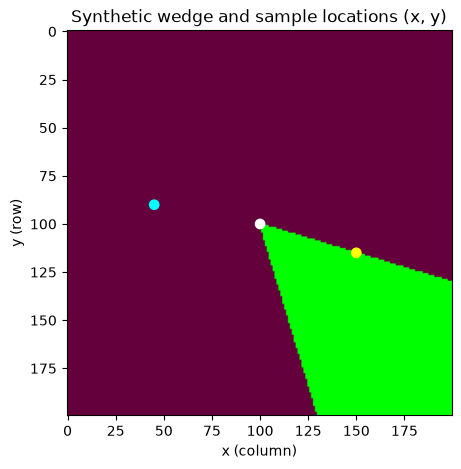

In [2]:
rgb=synthetic_wedge()
gray=grayscale(rgb)
fig,ax=plt.subplots(figsize=(5,5))
ax.imshow(rgb)
ax.scatter([100,45,150],[100,90,115],c=['white','cyan','yellow'],s=45)
ax.set_title("Synthetic wedge and sample locations (x, y)")
ax.set_xlabel("x (column)"); ax.set_ylabel("y (row)")
plt.show()

## 2. Local second-moment matrix

Compute Sobel derivatives on a **single grayscale channel**, then Gaussian-smooth the products $I_x^2$, $I_xI_y$, and $I_y^2$. This avoids mixing color channels with an arbitrary max operation.

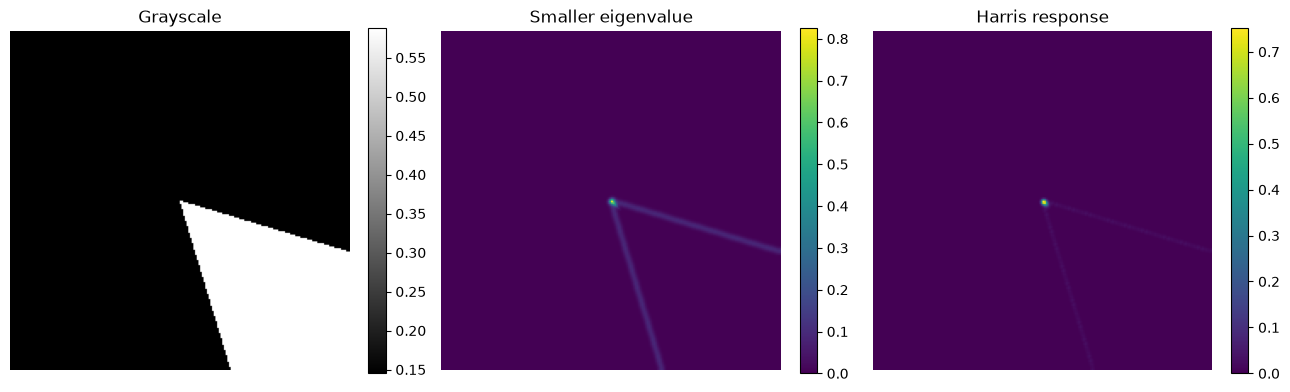

In [3]:
a,b,c=structure_tensor(gray,sigma=1.2)
response=harris_response(a,b,c,k=0.04)
lmax,lmin=eigenvalues(a,b,c)
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[gray,lmin,response],["Grayscale","Smaller eigenvalue","Harris response"]):
    im=ax.imshow(data,cmap="gray" if title=="Grayscale" else "viridis")
    ax.set_title(title); ax.axis("off"); fig.colorbar(im,ax=ax,fraction=.046)
plt.tight_layout(); plt.show()

## 3. Directional-energy polar plots

For unit direction $\mathbf{u}(\theta) = (\cos\theta, \sin\theta)$,
the local directional energy is

$$
E(\theta) = \mathbf{u}(\theta)^\top M \mathbf{u}(\theta).
$$
Its maximum and minimum over directions are the two eigenvalues of $M$. A flat patch has low energy in every direction; an edge has one strong and one weak direction; a corner has substantial energy in two independent directions.

**Coordinates:** NumPy images are indexed `[row, column] = [y, x]`. Sample locations below are explicitly specified as `(x, y)`. The point `(150,115)` is near the sloping wedge boundary, not necessarily an ideal edge at every smoothing scale.

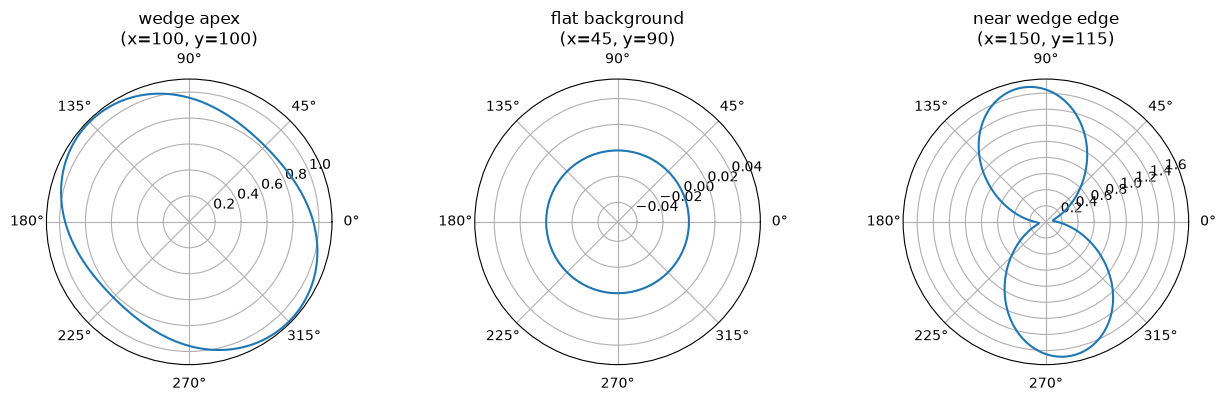

In [4]:
angles=np.linspace(0,2*np.pi,360,endpoint=False)
samples={"wedge apex":(100,100),"flat background":(45,90),"near wedge edge":(150,115)}
fig,axes=plt.subplots(1,3,figsize=(13,4),subplot_kw={"projection":"polar"})
for ax,(label,(x,y)) in zip(axes,samples.items()):
    energy=directional_energy(a[y:y+1,x:x+1],b[y:y+1,x:x+1],c[y:y+1,x:x+1],angles)[0,0]
    ax.plot(angles,energy)
    ax.set_title(f"{label}\n(x={x}, y={y})")
plt.tight_layout();plt.show()

## 4. Check the eigenvalue interpretation

Compare the extrema of the sampled directional energy with the structure-tensor eigenvalues. Discrete angular sampling approximates the extrema.

In [5]:
for label,(x,y) in samples.items():
    energy=directional_energy(a[y:y+1,x:x+1],b[y:y+1,x:x+1],c[y:y+1,x:x+1],angles)[0,0]
    print(f"{label:18s} min/max energy: {energy.min():.4g}/{energy.max():.4g}  eigenvalues: {lmin[y,x]:.4g}/{lmax[y,x]:.4g}  Harris R: {response[y,x]:.4g}")

wedge apex         min/max energy: 0.826/1.088  eigenvalues: 0.826/1.088  Harris R: 0.7521
flat background    min/max energy: 0/0  eigenvalues: 0/0  Harris R: 0
near wedge edge    min/max energy: 0.08804/1.695  eigenvalues: 0.08801/1.695  Harris R: 0.02202


## 5. Harris corner candidates

Threshold positive Harris responses relative to their maximum and apply local non-maximum suppression. This is a demonstration, not a benchmark detector.

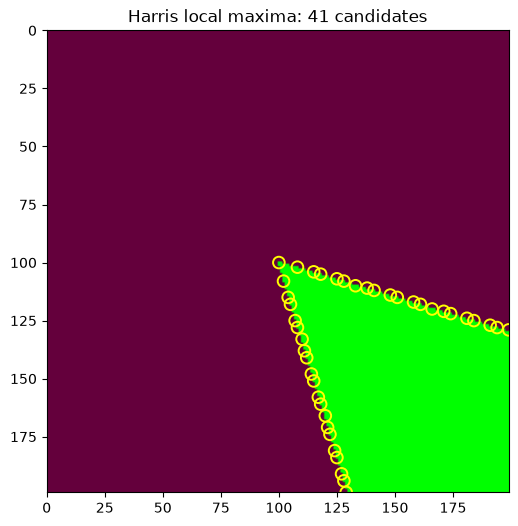

In [6]:
positive=np.maximum(response,0)
peak=cv2.dilate(positive,np.ones((5,5),np.uint8))
mask=(positive==peak)&(positive>0.02*positive.max())
ys,xs=np.where(mask)
fig,ax=plt.subplots(figsize=(6,6))
ax.imshow(rgb)
ax.scatter(xs,ys,facecolors="none",edgecolors="yellow",s=70,linewidths=1.4)
ax.set_title(f"Harris local maxima: {len(xs)} candidates")
ax.set_xlim(0,199);ax.set_ylim(199,0);plt.show()

## 6. Exercises

1. Derive $E(\theta) = a\cos^2\theta + 2b\sin\theta\cos\theta + c\sin^2\theta$
and show that its extrema are the eigenvalues of $M$.
2. Explain why the sign convention in the original directional derivative does **not** change the set of energies when all angles are sampled, even though it changes which angle labels attain extrema.
3. Vary Gaussian $\sigma$, Harris $k$, and the threshold. Which candidates are stable?
4. Replace the synthetic wedge with a checkerboard. Compare corner locations.
5. **Advanced:** Show how $R = \lambda_1\lambda_2 - k(\lambda_1+\lambda_2)^2$
distinguishes edge-like and corner-like neighborhoods.

**Limitations:** Sobel derivatives depend on scale; the synthetic wedge has rasterized boundaries; thresholding is heuristic; the notebook does not establish rotation/scale invariance or detector repeatability.